# Time-Series Preparation & Baseline Model
Target: **total daily sales** (sum over all stores). Steps: prepare the daily series, split chronologically (no shuffling), build seasonal-naive baselines, evaluate with RMSE, MAE and MAPE.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import Markdown, display

plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, GREY, ORANGE, RED, GREEN = '#2f80ed', '#9aa5b1', '#f2994a', '#d64545', '#27ae60'

# Colab: file next to the notebook. Repo: ../dataset/cleaned
for base in [Path('.'), Path('../dataset/cleaned')]:
    found = [p for p in [base/'cleaned_train.csv', base/'cleaned_train.zip'] if p.exists()]
    if found:
        DATA, train_path = base, found[0]
        break
OUT = Path('.') if DATA == Path('.') else Path('../dataset/forecasting')
OUT.mkdir(exist_ok=True)

cols = ['Date', 'Store', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']
df = pd.read_csv(train_path, usecols=cols, dtype={'StateHoliday': str}, parse_dates=['Date'])
df['IsStateHoliday'] = (df['StateHoliday'] != '0').astype(int)
print(df.shape, df['Date'].min().date(), '->', df['Date'].max().date())

(1017155, 9) 2013-01-01 -> 2015-07-31


## 1. Prepare the forecasting target (aggregate by date)

In [2]:
daily = df.groupby('Date').agg(Sales=('Sales', 'sum'), Customers=('Customers', 'sum'), OpenStores=('Open', 'sum'),
                               StoresReporting=('Store', 'nunique'), Promo=('Promo', 'mean'),
                               SchoolHoliday=('SchoolHoliday', 'mean'), StateHoliday=('IsStateHoliday', 'mean')).sort_index()

print('Promo is chain-wide (0 or 1 every day):', daily['Promo'].isin([0, 1]).all())
daily['Promo'] = daily['Promo'].round().astype(int)
daily['DayOfWeek'] = daily.index.dayofweek + 1

full = pd.date_range(daily.index.min(), daily.index.max(), freq='D')
assert daily.index.equals(full), 'missing dates'
assert daily.index.is_monotonic_increasing and (daily['Sales'] > 0).all()
daily.index = pd.DatetimeIndex(daily.index, freq='D')
print(f'{len(daily)} consecutive days, no gaps, no zero-sales days')
daily.tail()

Promo is chain-wide (0 or 1 every day): True
942 consecutive days, no gaps, no zero-sales days


,Sales,Customers,OpenStores,StoresReporting,Promo,SchoolHoliday,StateHoliday,DayOfWeek
Date,,,,,,,,
2015-07-27,10707292,970462,1113,1115,1,0.773094,0.0,1
2015-07-28,9115073,876092,1113,1115,1,0.773094,0.0,2
2015-07-29,8499962,828524,1113,1115,1,0.773094,0.0,3
2015-07-30,8798854,858547,1113,1115,1,0.838565,0.0,4
2015-07-31,10109742,968620,1113,1115,1,0.838565,0.0,5


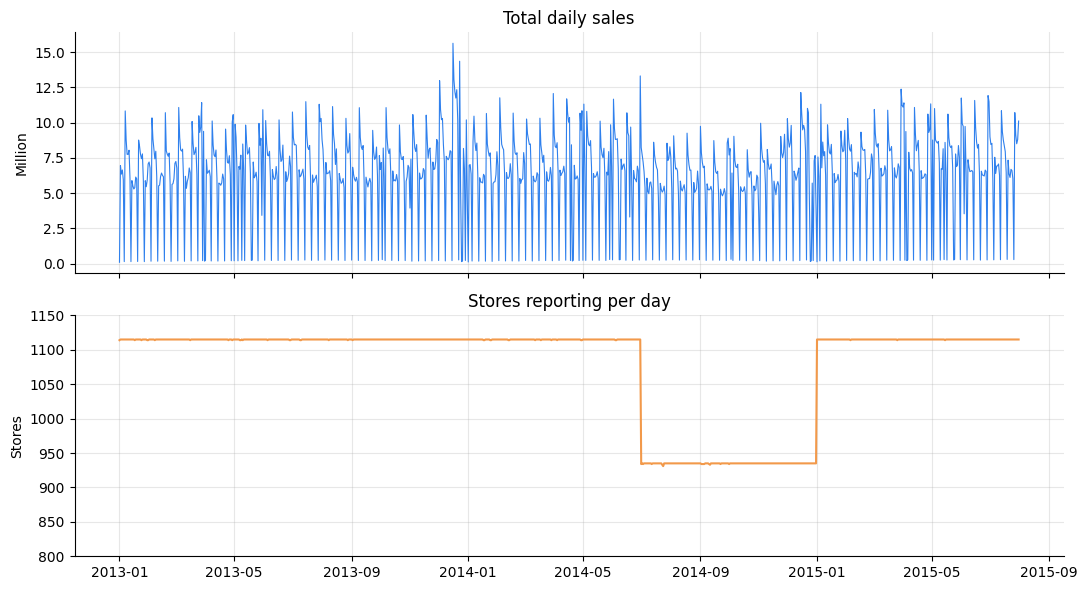

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(daily.index, daily['Sales'] / 1e6, color=BLUE, lw=0.8); axes[0].set(title='Total daily sales', ylabel='Million')
axes[1].plot(daily.index, daily['StoresReporting'], color=ORANGE); axes[1].set(title='Stores reporting per day', ylabel='Stores', ylim=(800, 1150))
plt.tight_layout(); plt.show()

About 180 stores are missing from July to December 2014, so total sales drop in that period for data reasons, not demand. `StoresReporting` is kept in the prepared data so later models can account for it.

## 2. Chronological split
Last **42 days (6 weeks)** are held out as the test set. No shuffling: the test period comes strictly after the training period.

In [4]:
H = 42
train, test = daily.iloc[:-H], daily.iloc[-H:]
assert train.index.max() < test.index.min()
assert test.index[0] == train.index[-1] + pd.Timedelta(days=1)
print(f'train: {train.index.min().date()} -> {train.index.max().date()} ({len(train)} days)')
print(f'test : {test.index.min().date()} -> {test.index.max().date()} ({len(test)} days)')
print('all stores report in the test period:', bool((test['StoresReporting'] == 1115).all()))

train: 2013-01-01 -> 2015-06-19 (900 days)
test : 2015-06-20 -> 2015-07-31 (42 days)
all stores report in the test period: True


## 3. Evaluation procedure
- **RMSE**, **MAE** (in sales units) and **MAPE** (%).
- `MAPE_normal_%` excludes Sundays/holidays (fewer than 800 open stores), where totals are tiny and MAPE explodes.
- **Hold-out:** the last 42 days. **Rolling-origin backtest:** 3 consecutive 42-day windows, each forecast from the data before it.

In [5]:
def evaluate(y_true, y_pred, normal=None):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    err = y_true - y_pred
    out = {'RMSE': np.sqrt(np.mean(err ** 2)), 'MAE': np.mean(np.abs(err)), 'MAPE_%': np.mean(np.abs(err) / y_true) * 100}
    if normal is not None:
        normal = np.asarray(normal)
        out['MAPE_normal_%'] = np.mean(np.abs(err[normal]) / y_true[normal]) * 100
    return out

normal_day = (daily['OpenStores'] >= 800)

## 4. Baseline models

In [6]:
y = daily['Sales']
MODELS = ['Naive (last value)', 'Seasonal naive (7d)', 'Seasonal naive (14d)', 'Seasonal naive (364d)']
PERIOD = {'Naive (last value)': 1, 'Seasonal naive (7d)': 7, 'Seasonal naive (14d)': 14}

def predict(name, n_train, horizon=H):
    # forecast `horizon` days after the first n_train days, using only those n_train days
    if name == 'Seasonal naive (364d)':                      # same weekday one year earlier
        return y.shift(364).iloc[n_train:n_train + horizon].to_numpy()
    m = PERIOD[name]
    return np.resize(y.iloc[n_train - m:n_train].to_numpy(), horizon)   # repeat the last cycle

n_train = len(train)
holdout_pred = pd.DataFrame({m: predict(m, n_train) for m in MODELS}, index=test.index)
holdout_pred.insert(0, 'Actual', test['Sales'].to_numpy())

holdout = pd.DataFrame({m: evaluate(test['Sales'], holdout_pred[m], normal_day.loc[test.index]) for m in MODELS}).T
holdout.round(1)

,RMSE,MAE,MAPE_%,MAPE_normal_%
Naive (last value),3512022.0,2507472.1,446.8,21.5
Seasonal naive (7d),1775080.2,1179019.2,17.4,19.5
Seasonal naive (14d),527462.3,354693.0,5.1,5.1
Seasonal naive (364d),1338134.7,1081606.2,14.7,15.7


`Seasonal naive (7d)` repeats the last week. `(14d)` repeats the last two weeks (captures a 2-week promo cycle, see section 6). `(364d)` uses the same weekday one year earlier. `Naive` repeats the last day and is only a sanity check.

## 5. Rolling-origin backtest

In [7]:
rows = []
for k in range(3):
    n_tr = len(y) - H * (k + 1)
    idx = y.index[n_tr:n_tr + H]
    for m in MODELS:
        rows.append({'fold': f'{idx[0]:%Y-%m-%d} -> {idx[-1]:%Y-%m-%d}', 'model': m, **evaluate(y.iloc[n_tr:n_tr + H], predict(m, n_tr), normal_day.loc[idx])})
backtest = pd.DataFrame(rows)
backtest_mean = backtest.groupby('model')[['RMSE', 'MAE', 'MAPE_%', 'MAPE_normal_%']].mean().loc[MODELS]
display(backtest.pivot(index='model', columns='fold', values='RMSE').loc[MODELS].round(0))
display(backtest_mean.round(1))

BASELINE = backtest_mean.loc[[m for m in MODELS if m != 'Naive (last value)'], 'RMSE'].idxmin()
print('Baseline to beat (lowest mean backtest RMSE):', BASELINE)

fold,2015-03-28 -> 2015-05-08,2015-05-09 -> 2015-06-19,2015-06-20 -> 2015-07-31
model,,,
Naive (last value),3802299.0,3998671.0,3512022.0
Seasonal naive (7d),3076103.0,2655513.0,1775080.0
Seasonal naive (14d),2540585.0,3610076.0,527462.0
Seasonal naive (364d),3525016.0,2403004.0,1338135.0


,RMSE,MAE,MAPE_%,MAPE_normal_%
model,,,,
Naive (last value),3770997.3,2744592.6,558.9,19.6
Seasonal naive (7d),2502232.2,1654472.2,130.7,19.9
Seasonal naive (14d),2226041.0,1367329.1,141.1,15.2
Seasonal naive (364d),2422051.8,1446568.2,127.4,16.5


Baseline to beat (lowest mean backtest RMSE): Seasonal naive (14d)


## 6. Hold-out forecast

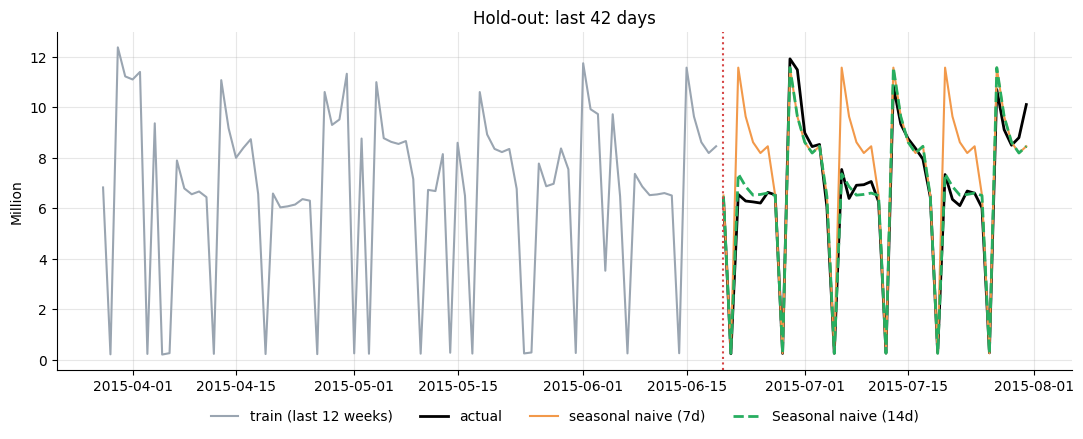

Weeks where promo flips vs previous week: 90%
Days where promo differs from the 7-day-earlier day: 15 of 42, giving 80% of the 7-day baseline absolute error


In [8]:
hist = y.iloc[-84 - H:-H]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(hist.index, hist / 1e6, color=GREY, label='train (last 12 weeks)')
ax.plot(test.index, test['Sales'] / 1e6, color='black', lw=2, label='actual')
ax.plot(test.index, holdout_pred['Seasonal naive (7d)'] / 1e6, color=ORANGE, label='seasonal naive (7d)')
ax.plot(test.index, holdout_pred[BASELINE] / 1e6, color=GREEN, ls='--', lw=2, label=BASELINE)
ax.axvline(test.index[0], color=RED, ls=':')
ax.set(title='Hold-out: last 42 days', ylabel='Million'); ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.08), frameon=False)
plt.tight_layout(); plt.show()

# where does the 7-day baseline go wrong? promo alternates week by week
ref = pd.Series(np.resize(train['Promo'].iloc[-7:].to_numpy(), H), index=test.index)
changed = (test['Promo'] != ref)
abs_err = (holdout_pred['Actual'] - holdout_pred['Seasonal naive (7d)']).abs()
share_changed = abs_err[changed].sum() / abs_err.sum()
weekly = daily.loc[daily['DayOfWeek'] <= 5, 'Promo'].groupby(pd.Grouper(freq='W-SUN')).mean()
alternating = (weekly.diff().abs() == 1).mean()
print(f'Weeks where promo flips vs previous week: {alternating:.0%}')
print(f'Days where promo differs from the 7-day-earlier day: {int(changed.sum())} of {H}, giving {share_changed:.0%} of the 7-day baseline absolute error')

## 7. Save prepared data, split and metrics

In [9]:
daily.to_csv(OUT / 'daily_sales.csv')
train.to_csv(OUT / 'train_daily.csv')
test.to_csv(OUT / 'test_daily.csv')
holdout_pred.to_csv(OUT / 'baseline_forecasts.csv', index_label='Date')
holdout.round(2).to_csv(OUT / 'baseline_metrics_holdout.csv', index_label='model')
backtest_mean.round(2).to_csv(OUT / 'baseline_metrics_backtest.csv', index_label='model')

chk = pd.read_csv(OUT / 'train_daily.csv', index_col='Date', parse_dates=True)
assert chk.index.max() < pd.read_csv(OUT / 'test_daily.csv', index_col='Date', parse_dates=True).index.min()
print('Saved to', OUT.resolve())

Saved to /home/claude/repo/dataset/forecasting


## 8. Summary

In [10]:
b, s7 = holdout.loc[BASELINE], holdout.loc['Seasonal naive (7d)']
fold_rmse = backtest.pivot(index='model', columns='fold', values='RMSE')
wins = int((fold_rmse.drop('Naive (last value)').idxmin() == BASELINE).sum())
display(Markdown(f'''
- **Target:** total daily sales, {len(daily)} days ({daily.index.min():%Y-%m-%d} to {daily.index.max():%Y-%m-%d}), no gaps.
- **Split:** train {len(train)} days, test the last {H} days ({test.index.min():%Y-%m-%d} to {test.index.max():%Y-%m-%d}), chronological.
- **Baseline to beat:** *{BASELINE}*. Hold-out RMSE {b['RMSE']:,.0f}, MAE {b['MAE']:,.0f}, MAPE {b['MAPE_%']:.1f}% (backtest mean RMSE {backtest_mean.loc[BASELINE, 'RMSE']:,.0f}).
- **Not best everywhere:** it has the lowest RMSE in {wins} of {fold_rmse.shape[1]} backtest folds; when the promo rhythm breaks, other variants do better, so it is a benchmark and not a strong model.
- **Plain weekly seasonal naive (7d):** hold-out RMSE {s7['RMSE']:,.0f}, MAE {s7['MAE']:,.0f}, MAPE {s7['MAPE_%']:.1f}%.
- **Why 14 days can beat 7:** promotions flip on/off in {alternating:.0%} of weeks, so the week before often has the opposite promo status. {share_changed:.0%} of the 7-day baseline error in the hold-out comes from days where promo status differed.
- **Next models** should use `Promo` (known in advance) and calendar/holiday features, and should be compared with this baseline on the same hold-out and backtest folds.
- **MAPE caveat:** over the backtest folds MAPE is inflated by Sundays/holidays with tiny totals; use `MAPE_normal_%` or RMSE/MAE for comparisons.
'''))


- **Target:** total daily sales, 942 days (2013-01-01 to 2015-07-31), no gaps.
- **Split:** train 900 days, test the last 42 days (2015-06-20 to 2015-07-31), chronological.
- **Baseline to beat:** *Seasonal naive (14d)*. Hold-out RMSE 527,462, MAE 354,693, MAPE 5.1% (backtest mean RMSE 2,226,041).
- **Not best everywhere:** it has the lowest RMSE in 2 of 3 backtest folds; when the promo rhythm breaks, other variants do better, so it is a benchmark and not a strong model.
- **Plain weekly seasonal naive (7d):** hold-out RMSE 1,775,080, MAE 1,179,019, MAPE 17.4%.
- **Why 14 days can beat 7:** promotions flip on/off in 90% of weeks, so the week before often has the opposite promo status. 80% of the 7-day baseline error in the hold-out comes from days where promo status differed.
- **Next models** should use `Promo` (known in advance) and calendar/holiday features, and should be compared with this baseline on the same hold-out and backtest folds.
- **MAPE caveat:** over the backtest folds MAPE is inflated by Sundays/holidays with tiny totals; use `MAPE_normal_%` or RMSE/MAE for comparisons.
